# PERSIAPAN LIBRARY & DATASET

In [99]:
import pandas as pd
import numpy as np
import requests
from mlxtend.frequent_patterns import fpgrowth, association_rules

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
!pip install --upgrade jupyter_client jupyter_core ipykernel


In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

Konversi ke datframe

### Cek Informasi awal Dataset

In [101]:
# url='https://archive.ics.uci.edu/static/public/352/data.csv'
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

# Download dataset
response = requests.get(url, timeout=180)
response.raise_for_status()

# Simpan file Excel
with open("Online_Retail.xlsx", "wb") as f:
    f.write(response.content)

In [102]:
# Baca dataset Excel
df = pd.read_excel("Online_Retail.xlsx")

print("="*4, "5 Baris Pertama", "="*4)
display(df.head())

==== 5 Baris Pertama ====


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [103]:
print('='*4, 'Ukuran Dataset', '='*4)
display(df.shape)

==== Ukuran Dataset ====


(541909, 8)

In [104]:
print("="*4, "Informasi DataSet", "="*4)
display(df.info())

==== Informasi DataSet ====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

# Eksplorasi dan Pembersihan Data

In [105]:
# Menampilkan Nama Kolom
display(df.columns.to_list())

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [106]:
# Cek missing value
df.isna().sum()/ len(df)*100

,0
InvoiceNo,0.000000
StockCode,0.000000
Description,0.268311
Quantity,0.000000
InvoiceDate,0.000000
UnitPrice,0.000000
CustomerID,24.926694
Country,0.000000


Hapus missing Value kolom Description dan transaksi yang dibatalkan serta seleksi kolom yang relevan

In [107]:
#Menampilkan beberapa baris kolom yang relevan saja
kolom_relevan= ['InvoiceNo', 'Description','Quantity','Country']
kolom_tersedia= [col for col in kolom_relevan if col in df.columns]

#Sample data Kolom relevan
print("="*4, "Sampel Data Kolom Relevan", "="*4)
display(df[kolom_tersedia].head())

==== Sampel Data Kolom Relevan ====


,InvoiceNo,Description,Quantity,Country
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,United Kingdom
1,536365,WHITE METAL LANTERN,6,United Kingdom
2,536365,CREAM CUPID HEARTS COAT HANGER,8,United Kingdom
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,United Kingdom
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,United Kingdom


In [108]:
# Menyimpan data umum & jumlah transaksi sebelum sebelum pembersihan
df_clean= df.copy()
jumlah_kotor= len(df_clean)
invoices_before = df_clean['InvoiceNo'].nunique()

In [109]:
# Pembersihan data menggunakan kolom 'invoice' & 'description'
df_clean= df_clean[kolom_tersedia]
df_clean['Description']= df_clean['Description'].dropna()
df_clean["Description"]= df_clean['Description'].astype(str).str.strip()


In [110]:
# Cek kolom deskripsi apakah sudah bersih
df_clean['Description'].isna().sum()

np.int64(0)

In [111]:
df_clean.isna().sum()

,0
InvoiceNo,0
Description,0
Quantity,0
Country,0


In [112]:
#MengHapus baris dengan Quantity bernilai negatif atau nol.
df_clean= df_clean[df_clean['Quantity']>0]

# Menghapus transaksi pembatalan(Invoice yg diawali 'C')
df_clean['InvoiceNo']= df_clean['InvoiceNo'].astype(str)
df_clean= df_clean[~ df_clean['InvoiceNo'].str.startswith("C")]

In [122]:
df_clean['InvoiceNo'].str.startswith("C").sum()

np.int64(0)

In [123]:
# Menyimpan jumlah transaksi setelah pembersihan
df_clean_final= df_clean.copy()
jumlah_bersih= len(df_clean_final)
invoices_after = df_clean_final['InvoiceNo'].nunique()

In [124]:
print("\n--- Hasil Pembersihan Data ---")
print(f"Jumlah baris sebelum : {jumlah_kotor:,}")
print(f"Jumlah baris sesudah : {jumlah_bersih:,}")
print(f"Jumlah invoice sebelum : {invoices_before:,}")
print(f"Jumlah invoice sesudah : {invoices_after:,}")


--- Hasil Pembersihan Data ---
Jumlah baris sebelum : 541,909
Jumlah baris sesudah : 531,285
Jumlah invoice sebelum : 25,900
Jumlah invoice sesudah : 20,728


# Persiapan Data (Basket/ One-Hot Encoding)

In [125]:
#Cek Negara
print("Jumlah negara yang terlibat: ",df_clean_final['Country'].nunique())

Jumlah negara yang terlibat:  38


In [126]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Bahrain', 'Greece', 'Hong Kong', 'Singapore',
       'Lebanon', 'United Arab Emirates', 'Saudi Arabia',
       'Czech Republic', 'Canada', 'Unspecified', 'Brazil', 'USA',
       'European Community', 'Malta', 'RSA'], dtype=object)

In [127]:
# Hapus kolom negara
df_clean_final= df_clean_final[['InvoiceNo','Description', "Quantity"]]
df_clean_final.columns

Index(['InvoiceNo', 'Description', 'Quantity'], dtype='object')

In [128]:
#Buat tabel basket terlebih dahulu, pastikan mengelompokkan berdasarkan InvoiceNo dan Description, lalu ambil quantity)
basket = df_clean_final.pivot_table(
    index='InvoiceNo',
    columns='Description',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

In [129]:
#Encoding: Ubah nilai yg >0 menjadi 1 dan yang 0 kebawah menjadi 0
def encode_units(x):
  return 1 if x>=1 else 0

In [130]:
# Mengubah nilai kuantitas menjadi biner (1 jika dibeli, 0 jika tidak)
basket_sets = basket.applymap(lambda x: 1 if x > 0 else 0)

In [131]:
basket.T.tail()

InvoiceNo,536365,536366,536367,536368,536369,536370,536371,536372,536373,536374,...,581581,581582,581583,581584,581585,581586,581587,A563185,A563186,A563187
Description,,,,,,,,,,,,,,,,,,,,,
wrongly coded 20713,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
wrongly coded 23343,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
wrongly marked,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
wrongly marked 23343,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
wrongly sold (22719) barcode,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Penerapan Algoritma FP-Growth

In [132]:
# Menggunakan apriori dengan minimum support 0.01
frequent_itemsets= fpgrowth(basket_sets, min_support=0.01, use_colnames=True)
print(f"Jumlah itemsets yang ditemukan: {len(frequent_itemsets)}")

Jumlah itemsets yang ditemukan: 1724


In [133]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.5
rules1= association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print(f"Jumlah rules yang dihasilkan: {len(rules1)}")

Jumlah rules yang dihasilkan: 736


In [134]:
rules1.tail(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
726,(SET OF 12 MINI LOAF BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.021420,0.026631,0.014763,0.689189,25.879553,1.0,0.014192,3.131710,0.982403,0.443478,0.680686,0.621769
727,(SET OF 12 FAIRY CAKE BAKING CASES),(SET OF 12 MINI LOAF BAKING CASES),0.026631,0.021420,0.014763,0.554348,25.879553,1.0,0.014192,2.195837,0.987662,0.443478,0.544593,0.621769
728,(SET OF 6 TEA TIME BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.018236,0.026631,0.012495,0.685185,25.729200,1.0,0.012010,3.091879,0.978987,0.385991,0.676572,0.577194
729,(SET OF 12 MINI LOAF BAKING CASES),(SET OF 6 TEA TIME BAKING CASES),0.021420,0.018236,0.011096,0.518018,28.406025,1.0,0.010705,2.036930,0.985915,0.388514,0.509065,0.563242
730,(SET OF 6 TEA TIME BAKING CASES),(SET OF 12 MINI LOAF BAKING CASES),0.018236,0.021420,0.011096,0.608466,28.406025,1.0,0.010705,2.499345,0.982717,0.388514,0.599895,0.563242
731,(SET OF 6 SNACK LOAF BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.017078,0.026631,0.012206,0.714689,26.837100,1.0,0.011751,3.411611,0.979466,0.387443,0.706883,0.586511
732,(SET OF 12 MINI LOAF BAKING CASES),(SET OF 6 SNACK LOAF BAKING CASES),0.021420,0.017078,0.011337,0.529279,30.991245,1.0,0.010971,2.088121,0.988916,0.417407,0.521100,0.596561
733,(SET OF 6 SNACK LOAF BAKING CASES),(SET OF 12 MINI LOAF BAKING CASES),0.017078,0.021420,0.011337,0.663842,30.991245,1.0,0.010971,2.911069,0.984547,0.417407,0.656484,0.596561
734,(JUMBO BAG VINTAGE DOILY),(JUMBO BAG RED RETROSPOT),0.034301,0.100926,0.017175,0.500703,4.961079,1.0,0.013713,1.800680,0.826791,0.145484,0.444654,0.335438
735,(HAND WARMER RED LOVE HEART),(HAND WARMER OWL DESIGN),0.019153,0.031552,0.010517,0.549118,17.403862,1.0,0.009913,2.147900,0.960946,0.261705,0.534429,0.441226


In [135]:
rules1.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,736.000000,736.000000,736.000000,736.000000,736.000000,736.0,736.000000,736.000000,736.000000,736.000000,736.000000,736.000000
mean,0.021749,0.050269,0.013608,0.645416,17.404295,1.0,0.012484,3.154935,0.940878,0.279332,0.626545,0.494664
std,0.007973,0.024411,0.004305,0.107805,13.278630,0.0,0.003800,1.927339,0.037032,0.145729,0.112980,0.117018
min,0.010517,0.011434,0.010035,0.500000,4.961079,1.0,0.008671,1.800680,0.821280,0.096118,0.444654,0.318445
25%,0.016596,0.034157,0.010855,0.555801,9.691301,1.0,0.010164,2.136092,0.919124,0.182661,0.531855,0.410322
50%,0.020021,0.049884,0.012302,0.622382,13.000321,1.0,0.011417,2.507775,0.945977,0.229733,0.601240,0.458547
75%,0.024701,0.058761,0.014521,0.721848,18.788371,1.0,0.013298,3.421562,0.968997,0.348987,0.707735,0.545684
max,0.061415,0.109031,0.039801,0.958716,80.536006,1.0,0.034533,23.394871,0.999152,0.863281,0.957256,0.926661


Jumlah itemsets dan rule yang ditemukan terlalu banyak

# Mencoba Parameter Lain

0.01 dan 0.6

In [136]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.6
rules2= association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)
print(f"Jumlah rules yang dihasilkan: {len(rules2)}")

Jumlah rules yang dihasilkan: 425


In [137]:
rules2.tail(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
415,(SET OF 3 WOODEN STOCKING DECORATION),(SET OF 3 WOODEN HEART DECORATIONS),0.015390,0.021469,0.010517,0.683386,31.831947,1.0,0.010187,3.090609,0.983724,0.399267,0.676439,0.586637
416,(SET OF 3 WOODEN STOCKING DECORATION),(SET OF 3 WOODEN TREE DECORATIONS),0.015390,0.014135,0.010565,0.686520,48.567216,1.0,0.010348,3.144908,0.994719,0.557252,0.682026,0.716980
417,(SET OF 3 WOODEN TREE DECORATIONS),(SET OF 3 WOODEN STOCKING DECORATION),0.014135,0.015390,0.010565,0.747440,48.567216,1.0,0.010348,3.898524,0.993453,0.557252,0.743493,0.716980
418,(SET OF 3 WOODEN TREE DECORATIONS),(SET OF 3 WOODEN HEART DECORATIONS),0.014135,0.021469,0.010179,0.720137,33.543797,1.0,0.009876,3.496460,0.984099,0.400380,0.713996,0.597147
419,(JUMBO BAG VINTAGE CHRISTMAS),(JUMBO BAG 50'S CHRISTMAS),0.022964,0.034543,0.015535,0.676471,19.583635,1.0,0.014741,2.984141,0.971241,0.370115,0.664895,0.563096
420,(SET OF 12 MINI LOAF BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.021420,0.026631,0.014763,0.689189,25.879553,1.0,0.014192,3.131710,0.982403,0.443478,0.680686,0.621769
421,(SET OF 6 TEA TIME BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.018236,0.026631,0.012495,0.685185,25.729200,1.0,0.012010,3.091879,0.978987,0.385991,0.676572,0.577194
422,(SET OF 6 TEA TIME BAKING CASES),(SET OF 12 MINI LOAF BAKING CASES),0.018236,0.021420,0.011096,0.608466,28.406025,1.0,0.010705,2.499345,0.982717,0.388514,0.599895,0.563242
423,(SET OF 6 SNACK LOAF BAKING CASES),(SET OF 12 FAIRY CAKE BAKING CASES),0.017078,0.026631,0.012206,0.714689,26.837100,1.0,0.011751,3.411611,0.979466,0.387443,0.706883,0.586511
424,(SET OF 6 SNACK LOAF BAKING CASES),(SET OF 12 MINI LOAF BAKING CASES),0.017078,0.021420,0.011337,0.663842,30.991245,1.0,0.010971,2.911069,0.984547,0.417407,0.656484,0.596561


In [138]:
rules2.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,425.000000,425.000000,425.000000,425.000000,425.000000,425.0,425.000000,425.000000,425.000000,425.000000,425.000000,425.000000
mean,0.018977,0.052046,0.013378,0.717407,19.943717,1.0,0.012362,3.919405,0.944210,0.297245,0.701490,0.532341
std,0.006976,0.027444,0.004445,0.085203,15.839639,0.0,0.003994,2.244810,0.038493,0.174102,0.090063,0.124827
min,0.010517,0.011434,0.010035,0.600000,5.955069,1.0,0.008671,2.253448,0.848073,0.096118,0.556236,0.356678
25%,0.014714,0.034157,0.010758,0.645783,10.115071,1.0,0.010073,2.683772,0.919342,0.174961,0.627390,0.441686
50%,0.017416,0.049884,0.012109,0.703927,15.455526,1.0,0.011228,3.188839,0.952718,0.235174,0.686406,0.492673
75%,0.020648,0.061415,0.014087,0.770898,20.724144,1.0,0.013083,4.102932,0.973927,0.377444,0.756272,0.577447
max,0.058761,0.109031,0.039801,0.958716,80.536006,1.0,0.034533,23.394871,0.999152,0.863281,0.957256,0.926661


0.02 dan 0.5

In [139]:
# Menggunakan apriori dengan minimum support 0.02
basket_sets2= basket_sets.copy()
frequent_itemsets2= fpgrowth(basket_sets2, min_support=0.02, use_colnames=True)
print(f"Jumlah itemsets yang ditemukan: {len(frequent_itemsets2)}")

Jumlah itemsets yang ditemukan: 348


In [140]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.5

rules3= association_rules(frequent_itemsets2, metric="confidence", min_threshold=0.5)
print(f"Jumlah rules yang dihasilkan: {len(rules3)}")

Jumlah rules yang dihasilkan: 51


In [141]:
rules3.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.0,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,0.043222,0.063451,0.026492,0.621226,11.365976,1.0,0.023733,2.760175,0.936008,0.364465,0.595073,0.552204
std,0.007671,0.025574,0.004380,0.094284,4.435004,0.0,0.004111,1.362437,0.045588,0.121766,0.101222,0.111767
min,0.028898,0.028898,0.020021,0.501478,5.226060,1.0,0.016379,1.813446,0.848717,0.171134,0.448564,0.376594
25%,0.036955,0.043733,0.023832,0.550957,6.708248,1.0,0.020769,2.074765,0.891804,0.264250,0.518012,0.452604
50%,0.041731,0.051428,0.026003,0.605988,12.028865,1.0,0.023517,2.384236,0.954632,0.359830,0.580578,0.531557
75%,0.048968,0.098442,0.028560,0.674954,14.712801,1.0,0.025024,2.820450,0.973854,0.468453,0.645395,0.659173
max,0.061415,0.109031,0.039801,0.904841,19.097068,1.0,0.034533,9.994183,0.994585,0.584920,0.899942,0.738550


0.02 dan 0.6

In [142]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.6

rules4= association_rules(frequent_itemsets2, metric="confidence", min_threshold=0.6)
print(f"Jumlah rules yang dihasilkan: {len(rules4)}")

Jumlah rules yang dihasilkan: 27


In [143]:
rules4.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,27.000000,27.000000,27.000000,27.000000,27.000000,27.0,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000
mean,0.040664,0.065569,0.027755,0.688715,12.199040,1.0,0.025069,3.369869,0.940727,0.394892,0.665840,0.588671
std,0.007832,0.026550,0.004855,0.078623,4.619649,0.0,0.004592,1.651919,0.045158,0.134964,0.087065,0.111177
min,0.028898,0.036955,0.020745,0.600255,6.058744,1.0,0.017395,2.314138,0.867305,0.182979,0.567874,0.415272
25%,0.035797,0.048968,0.024797,0.626005,6.708248,1.0,0.021799,2.497577,0.884177,0.261727,0.599371,0.468608
50%,0.037775,0.050704,0.026148,0.673171,12.879784,1.0,0.024578,2.786442,0.963534,0.415936,0.641119,0.603696
75%,0.046145,0.100926,0.030538,0.713944,15.779445,1.0,0.028479,3.347478,0.974259,0.495702,0.701188,0.694496
max,0.058761,0.109031,0.039801,0.904841,19.097068,1.0,0.034533,9.994183,0.989182,0.584920,0.899942,0.738550


0.03 dan 0.5

In [144]:
# Menggunakan apriori dengan minimum support 0.03
basket_sets3= basket_sets.copy()
frequent_itemsets3= fpgrowth(basket_sets3, min_support=0.03, use_colnames=True)
print(f"Jumlah itemsets yang ditemukan: {len(frequent_itemsets3)}")

Jumlah itemsets yang ditemukan: 125


In [145]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.5

rules5= association_rules(frequent_itemsets3, metric="confidence", min_threshold=0.5)
print(f"Jumlah rules yang dihasilkan: {len(rules5)}")

Jumlah rules yang dihasilkan: 10


0.03 dan 0.6

In [146]:
#Menghasilkan Association Rule dengan minimum Confidene support 0.6

rules6= association_rules(frequent_itemsets3, metric="confidence", min_threshold=0.6)
print(f"Jumlah rules yang dihasilkan: {len(rules6)}")

Jumlah rules yang dihasilkan: 8


# EVALUASI Jumlah Rule & Itemset pada masing masing Percobaan

In [147]:
print("=="*5,"PERBANDINGAN ANTAR SKENARIO","=="*5)
support=[0.01, 0.02, 0.03]
confidence= [0.5, 0.6]

for i in range(len(support)):
  print("---"*4,"Min_Support:",support[i],"---"*4)
  for j in range(len(confidence)):
    print("Min_Confidence:",confidence[j])
    if i==0:
      print(f"Jumlah Itemset: {len(globals()[f'frequent_itemsets'])}", f"Jumlah Rule: {len(globals()[f'rules{0+j+1}'])}")
    elif i==2:
      print(f"Jumlah Itemset: {len(globals()[f'frequent_itemsets{i+1}'])}", f"Jumlah Rule: {len(globals()[f'rules{i+j+3}'])}")
    else:
      print(f"Jumlah Itemset: {len(globals()[f'frequent_itemsets{i+1}'])}", f"Jumlah Rule: {len(globals()[f'rules{i+j+2}'])}")
  print("------"*7)
  print()

# for index, item in enumerate(support,start=1):
#   for idx, itm in enumerate(confidence, start=1):
#       print(index, idx)
#       print(f"Min.Support: {item}", f"Min.Confidence: {itm}")

========== PERBANDINGAN ANTAR SKENARIO ==========
------------ Min_Support: 0.01 ------------
Min_Confidence: 0.5
Jumlah Itemset: 1724 Jumlah Rule: 736
Min_Confidence: 0.6
Jumlah Itemset: 1724 Jumlah Rule: 425
------------------------------------------

------------ Min_Support: 0.02 ------------
Min_Confidence: 0.5
Jumlah Itemset: 348 Jumlah Rule: 51
Min_Confidence: 0.6
Jumlah Itemset: 348 Jumlah Rule: 27
------------------------------------------

------------ Min_Support: 0.03 ------------
Min_Confidence: 0.5
Jumlah Itemset: 125 Jumlah Rule: 10
Min_Confidence: 0.6
Jumlah Itemset: 125 Jumlah Rule: 8
------------------------------------------



Terlihat bahwa semakin tinggi min support secara gak signifikan, jumlah itemset semakin berkurang secara signifikan. Semakin tinggi penambahan min confidence jumlah rule juga semakin berkurang secara tidak signifikan (tidak drastis) dan bergantung pada minimal support.

### Seleksi Parameter terbaik dengan melihat mean tertinggi dan skewness tidak ekstrem

In [148]:
aturan= [rules1, rules2, rules3, rules4, rules5, rules6]
for i in aturan:
  kandidat= i
  print(f"Mean lift: {i['lift'].mean()}, skewness= {i['lift'].skew()}")

Mean lift: 17.404295353902075, skewness= 2.6415214340955826
Mean lift: 19.943716535873087, skewness= 2.2046431108071736
Mean lift: 11.365976002859044, skewness= 0.08381093108423454
Mean lift: 12.199040421779076, skewness= -0.1846015988690076
Mean lift: 11.411446633599045, skewness= -0.2012195790420746
Mean lift: 12.713362317913443, skewness= -0.9067219427914338


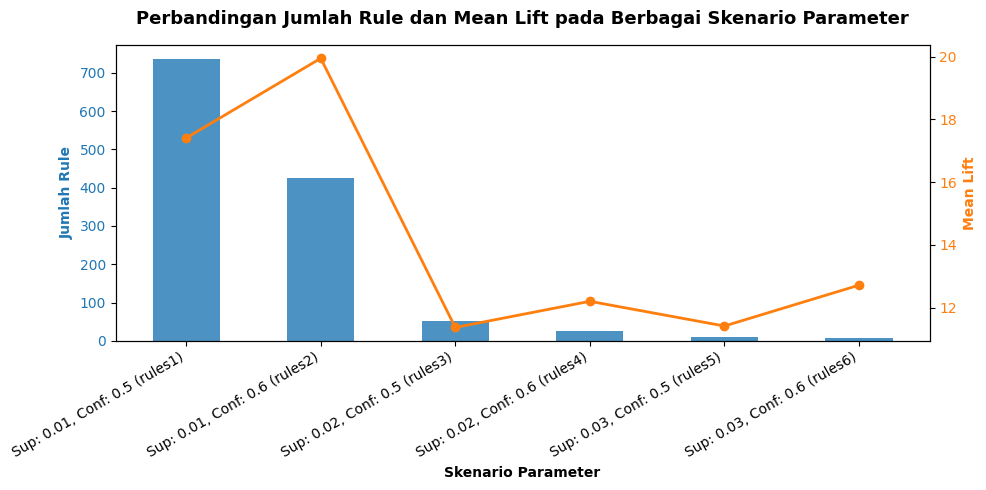

In [149]:
skenario_labels = [
    'Sup: 0.01, Conf: 0.5 (rules1)',
    'Sup: 0.01, Conf: 0.6 (rules2)',
    'Sup: 0.02, Conf: 0.5 (rules3)',
    'Sup: 0.02, Conf: 0.6 (rules4)',
    'Sup: 0.03, Conf: 0.5 (rules5)',
    'Sup: 0.03, Conf: 0.6 (rules6)'
]

jumlah_rules = [len(rules1), len(rules2), len(rules3), len(rules4), len(rules5), len(rules6)]
mean_lifts = [rules1['lift'].mean(), rules2['lift'].mean(), rules3['lift'].mean(),
              rules4['lift'].mean(), rules5['lift'].mean(), rules6['lift'].mean()]
skews = [rules1['lift'].skew(), rules2['lift'].skew(), rules3['lift'].skew(),
         rules4['lift'].skew(), rules5['lift'].skew(), rules6['lift'].skew()]

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar plot untuk Jumlah Rule
color = 'tab:blue'
ax1.set_xlabel('Skenario Parameter', fontweight='bold')
ax1.set_ylabel('Jumlah Rule', color=color, fontweight='bold')
bars = ax1.bar(skenario_labels, jumlah_rules, color=color, alpha=0.8, width=0.5)
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=30, ha='right')

# Line plot untuk Mean Lift pada sumbu Y kedua
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Mean Lift', color=color, fontweight='bold')
line = ax2.plot(skenario_labels, mean_lifts, color=color, marker='o', linewidth=2, label='Mean Lift')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False) # Menghindari tumpang tindih grid

plt.title('Perbandingan Jumlah Rule dan Mean Lift pada Berbagai Skenario Parameter', fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

Terdapat 2 rule pertimbangan sebagai berikut:
- rules2 (min_sup= 0.01, confid= 0.5) memiliki rerata lift tertinggi sebesar 19.9 namun skewnessnya besar 2.2, 1724 itemset dan jumlah rulenya tinggi yakni 425
- rules4 (min_sup=0.02, confid= 0.6) memiliki rerata lift 12.19 (urutan 4) yang bagusnya terdistribusi normal karena skewness nya mendekati 0, memiliki 348 itemsets dan jumlah rule nya tidak terlalu banyak yakni 27.

In [150]:
rules2.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,425.000000,425.000000,425.000000,425.000000,425.000000,425.0,425.000000,425.000000,425.000000,425.000000,425.000000,425.000000
mean,0.018977,0.052046,0.013378,0.717407,19.943717,1.0,0.012362,3.919405,0.944210,0.297245,0.701490,0.532341
std,0.006976,0.027444,0.004445,0.085203,15.839639,0.0,0.003994,2.244810,0.038493,0.174102,0.090063,0.124827
min,0.010517,0.011434,0.010035,0.600000,5.955069,1.0,0.008671,2.253448,0.848073,0.096118,0.556236,0.356678
25%,0.014714,0.034157,0.010758,0.645783,10.115071,1.0,0.010073,2.683772,0.919342,0.174961,0.627390,0.441686
50%,0.017416,0.049884,0.012109,0.703927,15.455526,1.0,0.011228,3.188839,0.952718,0.235174,0.686406,0.492673
75%,0.020648,0.061415,0.014087,0.770898,20.724144,1.0,0.013083,4.102932,0.973927,0.377444,0.756272,0.577447
max,0.058761,0.109031,0.039801,0.958716,80.536006,1.0,0.034533,23.394871,0.999152,0.863281,0.957256,0.926661


In [151]:
rules4.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,27.000000,27.000000,27.000000,27.000000,27.000000,27.0,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000
mean,0.040664,0.065569,0.027755,0.688715,12.199040,1.0,0.025069,3.369869,0.940727,0.394892,0.665840,0.588671
std,0.007832,0.026550,0.004855,0.078623,4.619649,0.0,0.004592,1.651919,0.045158,0.134964,0.087065,0.111177
min,0.028898,0.036955,0.020745,0.600255,6.058744,1.0,0.017395,2.314138,0.867305,0.182979,0.567874,0.415272
25%,0.035797,0.048968,0.024797,0.626005,6.708248,1.0,0.021799,2.497577,0.884177,0.261727,0.599371,0.468608
50%,0.037775,0.050704,0.026148,0.673171,12.879784,1.0,0.024578,2.786442,0.963534,0.415936,0.641119,0.603696
75%,0.046145,0.100926,0.030538,0.713944,15.779445,1.0,0.028479,3.347478,0.974259,0.495702,0.701188,0.694496
max,0.058761,0.109031,0.039801,0.904841,19.097068,1.0,0.034533,9.994183,0.989182,0.584920,0.899942,0.738550


### Keputusan pemilihan Parameter  
Parameter dengan min.sup= 0.02 dan min.confidence= 0.6 dipilih karena menghasilkan jumlah aturan asosiasi yang terkendali (tidak terlalu banyak dan sedikit) sebanyak **`27 rule`**, sehingga mudah dianalisis.  
Skenario ini memiliki mean lift sebesar 12,19 serta skewness -0.18 (melenceng sedikit).  
Skenario ini dipilih karena menurut saya seimbang antara jumlah rule, tingkat confidence, dan karakteristik distribusi lift

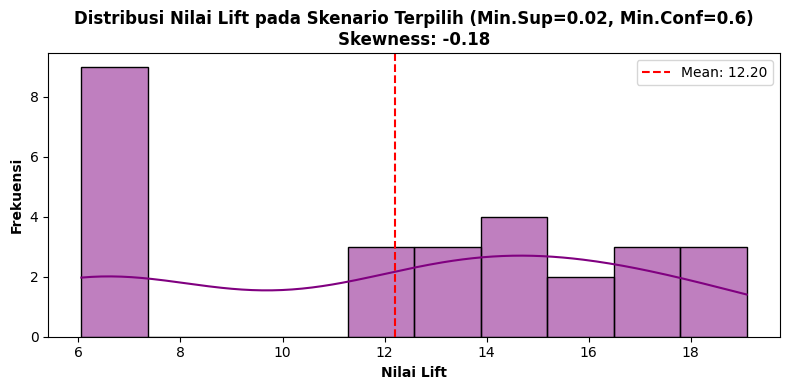

In [152]:
plt.figure(figsize=(8, 4))
sns.histplot(rules4['lift'], kde=True, color='purple', bins=10)
plt.axvline(rules4['lift'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {rules4['lift'].mean():.2f}")
plt.title(f'Distribusi Nilai Lift pada Skenario Terpilih (Min.Sup=0.02, Min.Conf=0.6)\nSkewness: {rules4["lift"].skew():.2f}', fontweight='bold')
plt.xlabel('Nilai Lift', fontweight='bold')
plt.ylabel('Frekuensi', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

# 3 Aturan Terbaik Berdasar Lift-Ratio

In [153]:
top_rules= rules4.sort_values(by="lift", ascending=False).head(3)
top_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
23,"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",(PINK REGENCY TEACUP AND SAUCER),0.037051,0.036955,0.026148,0.705729,19.097068,1.0,0.024779,3.272649,0.984098,0.546371,0.694437,0.706650
24,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",0.036955,0.037051,0.026148,0.707572,19.097068,1.0,0.024779,3.292941,0.983999,0.546371,0.696320,0.706650
21,"(PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY...",(GREEN REGENCY TEACUP AND SAUCER),0.028898,0.048968,0.026148,0.904841,18.478377,1.0,0.024733,9.994183,0.974030,0.505597,0.899942,0.719416


In [154]:
for idx, row in top_rules.reset_index(drop=True).iterrows():
    antecedents = list(row['antecedents'])
    consequents = list(row['consequents'])
    print(f"\nAturan {idx+1}:")
    print(f"  Jika membeli       : {antecedents}")
    print(f"  Maka membeli       : {consequents}")
    print(f"  - Support          : {row['support']:.4f}")
    print(f"  - Confidence       : {row['confidence']:.4f}")
    print(f"  - Lift             : {row['lift']:.4f}")
    # print(f"  - Representativity : {row['representativity']:.4f}")
    # print(f"  - Leverage         : {row['leverage']:.4f}")
    # print(f"  - Conviction       : {row['conviction']:.4f}")
    # print(f"  - Zhangs_Metric    : {row['zhangs_metric']:.4f}")
    # print(f"  - Jaccard          : {row['jaccard']:.4f}")
    # print(f"  - Certainty        : {row['certainty']:.4f}")
    # print(f"  - Kulczynski       : {row['kulczynski']:.4f}")

# kolom=[representativity	leverage	conviction	zhangs_metric	jaccard	certainty	kulczynski]


Aturan 1:
  Jika membeli       : ['ROSES REGENCY TEACUP AND SAUCER', 'GREEN REGENCY TEACUP AND SAUCER']
  Maka membeli       : ['PINK REGENCY TEACUP AND SAUCER']
  - Support          : 0.0261
  - Confidence       : 0.7057
  - Lift             : 19.0971

Aturan 2:
  Jika membeli       : ['PINK REGENCY TEACUP AND SAUCER']
  Maka membeli       : ['ROSES REGENCY TEACUP AND SAUCER', 'GREEN REGENCY TEACUP AND SAUCER']
  - Support          : 0.0261
  - Confidence       : 0.7076
  - Lift             : 19.0971

Aturan 3:
  Jika membeli       : ['PINK REGENCY TEACUP AND SAUCER', 'ROSES REGENCY TEACUP AND SAUCER']
  Maka membeli       : ['GREEN REGENCY TEACUP AND SAUCER']
  - Support          : 0.0261
  - Confidence       : 0.9048
  - Lift             : 18.4784


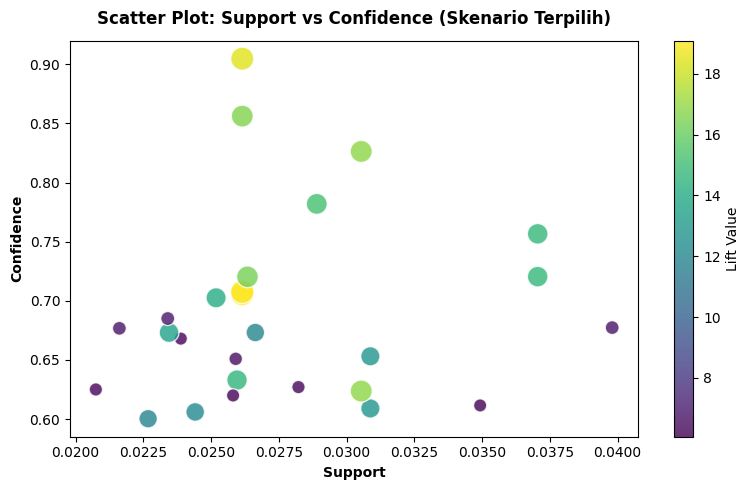

In [155]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    rules4['support'],
    rules4['confidence'],
    c=rules4['lift'],
    cmap='viridis',
    s=rules4['lift']*15, # Ukuran titik berdasarkan lift
    alpha=0.8,
    edgecolors='w'
)
plt.colorbar(scatter, label='Lift Value')
plt.title('Scatter Plot: Support vs Confidence (Skenario Terpilih)', fontweight='bold', pad=12)
plt.xlabel('Support', fontweight='bold')
plt.ylabel('Confidence', fontweight='bold')
plt.tight_layout()
plt.show()

Berdasarkan grafik Scatter Plot di atas, sebaran 27 aturan asosiasi dapat diinterpretasi dengan tiga metrik utama:  
1.  **`Support`**: Sebagian besar rule berkumpul pada rentang support 0.02 hingga kurang dari 0.0325. Rule tertinggi berada di kisaran support 0.04 (4% dari transaksi).  
2.  **`Confidence`**: maksimum nilai confidence adalah 0.9  
3.  **`Lift`**: titik yang ditandai dengan warna kuning dan radius lingkaran yang besar menunjukkan aturan dengan nilai lift >18.


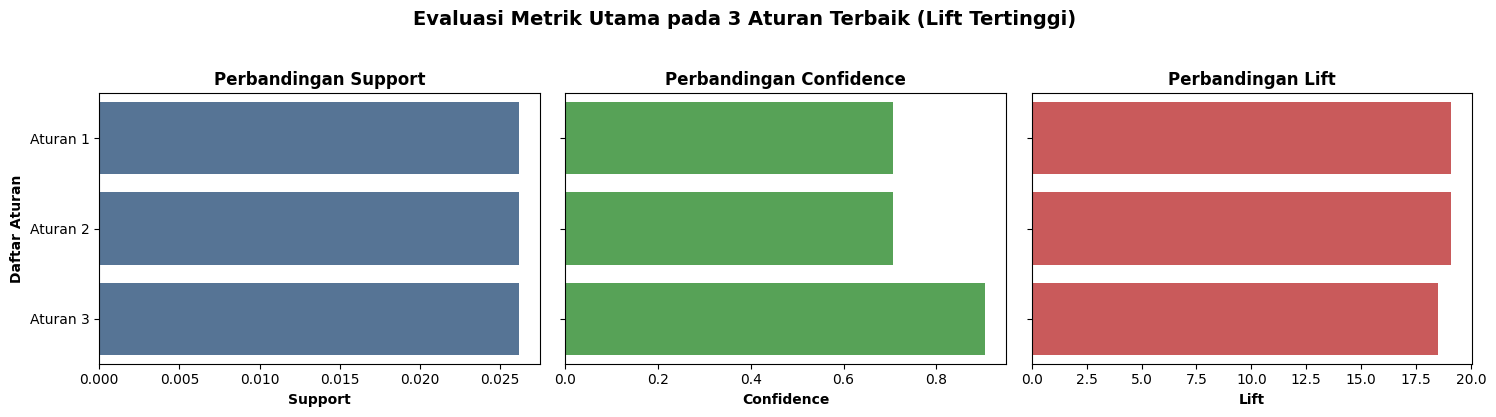

In [156]:
top_rules_vis = top_rules.copy()
top_rules_vis['Rule_Name'] = [f"Aturan {i+1}" for i in range(len(top_rules_vis))]

# Membuat plot batang horizontal untuk membandingkan Support, Confidence, dan Lift
metrics_to_plot = ['support', 'confidence', 'lift']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

colors = ['#2b5c8f', '#2ca02c', '#d62728']
for idx, metric in enumerate(metrics_to_plot):
    sns.barplot(
        x=metric,
        y='Rule_Name',
        data=top_rules_vis,
        ax=axes[idx],
        color=colors[idx],
        alpha=0.85
    )
    axes[idx].set_title(f'Perbandingan {metric.capitalize()}', fontweight='bold')
    axes[idx].set_xlabel(metric.capitalize(), fontweight='bold')
    if idx == 0:
        axes[idx].set_ylabel('Daftar Aturan', fontweight='bold')
    else:
        axes[idx].set_ylabel('')

plt.suptitle('Evaluasi Metrik Utama pada 3 Aturan Terbaik (Lift Tertinggi)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

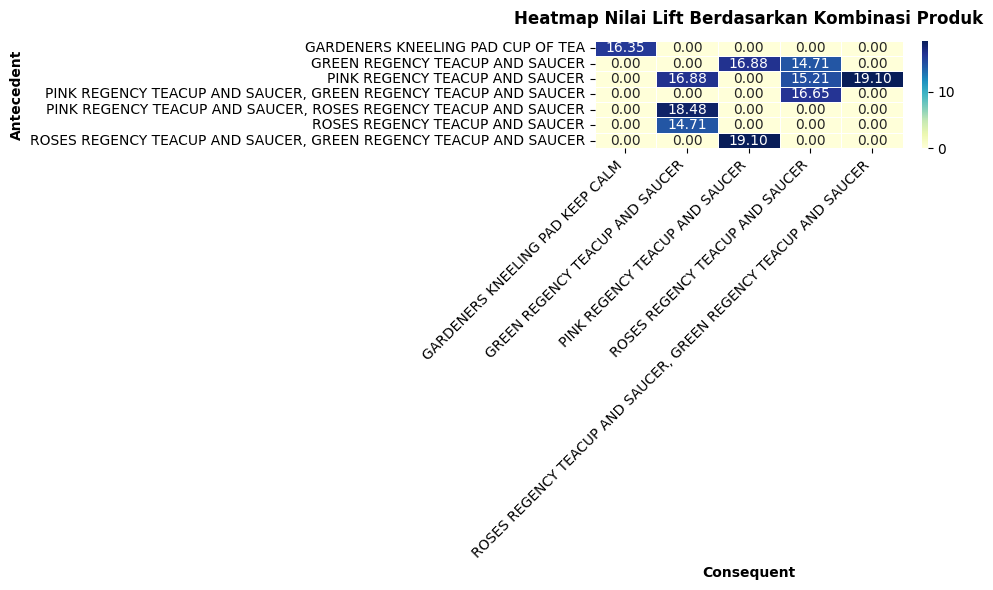

In [157]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Menyiapkan data untuk heatmap dari top rules (misal top 10)
heatmap_data = rules4.sort_values(by='lift', ascending=False).head(10).copy()
heatmap_data['Antecedent'] = heatmap_data['antecedents'].apply(lambda x: ", ".join(list(x)))
heatmap_data['Consequent'] = heatmap_data['consequents'].apply(lambda x: ", ".join(list(x)))

# Membuat pivot table untuk heatmap
pivot_heatmap = heatmap_data.pivot(index='Antecedent', columns='Consequent', values='lift').fillna(0)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_heatmap, annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5)
plt.title('Heatmap Nilai Lift Berdasarkan Kombinasi Produk', fontweight='bold', pad=12)
plt.xlabel('Consequent', fontweight='bold')
plt.ylabel('Antecedent', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()